# ¿Qué clientes sostienen las ventas y cuánto se pierde si se van?

Segmentación RFM de los clientes de una distribuidora de bebidas **ficticia** de Santa Cruz: tiendas de barrio, kioscos, minimercados, restaurantes y mayoristas, con pedidos de octubre de 2024 a septiembre de 2026 y montos en bolivianos (Bs).

**Respuesta corta:**

1. El 20% de los clientes hace el 71% de las ventas. Campeones y Leales son el 30% de los clientes y el 61% de las ventas.
2. Hay 202 clientes "En riesgo": compraban seguido, pero hace semanas que no compran. Juntos compran Bs 8,7 millones al año.
3. La segmentación anticipa bien. De los clientes que estaban "En riesgo" hace un año, 3 de cada 10 dejaron de comprar y sus compras cayeron 35%.
4. Si se repite, se pierden unos Bs 3,0 millones al año. Recuperar la mitad vale unos Bs 1,5 millones.
5. Primero hay que visitar a los 50 clientes en riesgo más grandes, que son el 65% de esa venta, y revisar las rutas R07, R15 y R11.

> Los datos se generan con `generar_datos.py` (semilla fija, así que los resultados se reproducen). Los números ilustran el método: no describen a ninguna empresa real.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

import graficos as g

g.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATOS, IMG, RESULTADOS = Path("datos"), Path("img"), Path("resultados")
IMG.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

clientes = pd.read_csv(DATOS / "clientes.csv", parse_dates=["fecha_alta"])
ventas = pd.read_csv(DATOS / "ventas.csv", parse_dates=["fecha"])
CORTE = pd.Timestamp("2026-09-30")

print(f"{len(clientes):,} clientes | {len(ventas):,} pedidos | "
      f"{ventas['fecha'].min():%d/%m/%Y} a {ventas['fecha'].max():%d/%m/%Y}")

1,776 clientes | 100,857 pedidos | 01/10/2024 a 30/09/2026


## 1. Los datos

- `clientes.csv`: una fila por cliente, con tipo de negocio, zona, ruta de preventa y fecha de alta.
- `ventas.csv`: una fila por pedido, con fecha, cajas y monto en bolivianos.

Los datos **no dicen** qué clientes dejaron de comprar. Eso es lo que la segmentación tiene que descubrir.

Primero, una foto de los últimos 12 meses por tipo de cliente.

In [2]:
inicio_12m = CORTE - pd.DateOffset(years=1) + pd.Timedelta(days=1)
ultimo_anio = ventas[ventas["fecha"].between(inicio_12m, CORTE)].merge(clientes, on="id_cliente")

por_tipo = ultimo_anio.groupby("tipo").agg(
    clientes=("id_cliente", "nunique"), pedidos=("id_pedido", "count"), ventas_bs=("monto_bs", "sum"))
por_tipo["ticket_promedio_bs"] = por_tipo["ventas_bs"] / por_tipo["pedidos"]
por_tipo["participacion_ventas"] = por_tipo["ventas_bs"] / por_tipo["ventas_bs"].sum()

ventas_12m = ultimo_anio["monto_bs"].sum()
print(f"Ventas de los últimos 12 meses: {g.bs(ventas_12m)} en {ultimo_anio['id_cliente'].nunique():,} clientes")
por_tipo.sort_values("ventas_bs", ascending=False)

Ventas de los últimos 12 meses: Bs 58.433.300 en 1,525 clientes


,clientes,pedidos,ventas_bs,ticket_promedio_bs,participacion_ventas
tipo,,,,,
Mayorista,91,4877,24400532,"5,003.18",0.42
Minimercado,273,10577,15936972,"1,506.76",0.27
Tienda de barrio,708,24458,11681160,477.60,0.20
Restaurante o pensión,200,5753,4888320,849.70,0.08
Kiosco,253,5929,1526316,257.43,0.03


## 2. ¿Quién sostiene las ventas?

Se ordena a los clientes de mayor a menor compra y se acumulan sus ventas (curva de Pareto).

In [3]:
venta_cliente = ultimo_anio.groupby("id_cliente")["monto_bs"].sum().sort_values(ascending=False)
acumulado = venta_cliente.cumsum() / venta_cliente.sum()
pct_clientes = np.arange(1, len(venta_cliente) + 1) / len(venta_cliente)

top20 = acumulado.iloc[int(np.ceil(0.2 * len(venta_cliente))) - 1]
clientes_mitad = int((acumulado < 0.5).sum() + 1)
print(f"El 20% de los clientes hace el {g.porcentaje(top20)} de las ventas")
print(f"La mitad de las ventas la hacen {clientes_mitad} clientes "
      f"({g.porcentaje(clientes_mitad / len(venta_cliente), 1)} del total)")

El 20% de los clientes hace el 71% de las ventas
La mitad de las ventas la hacen 115 clientes (7,5% del total)


PosixPath('img/01_pareto.png')

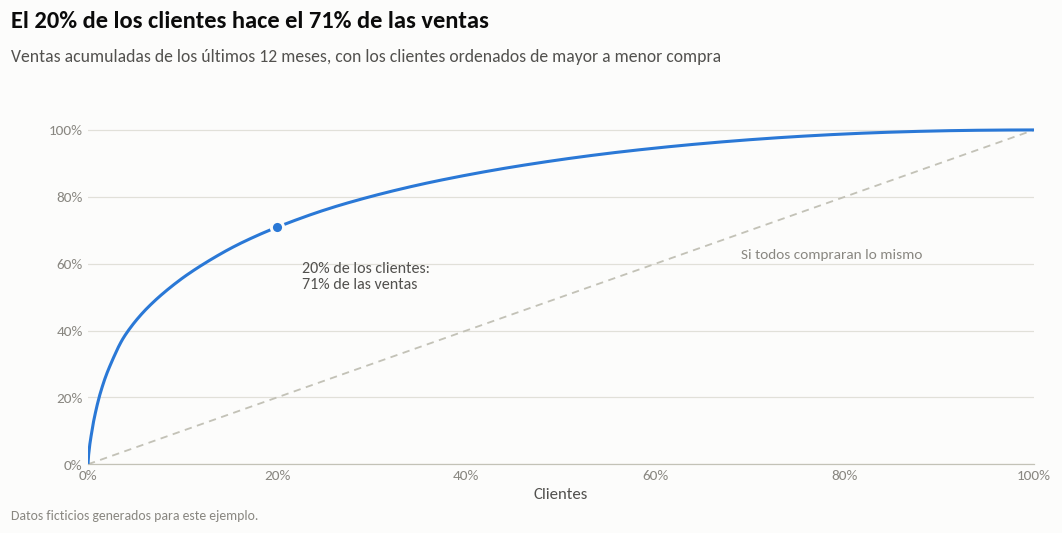

In [4]:
fig, ax = g.figura(alto=5.0, ejes=(0.09, 0.13, 0.86, 0.62))
g.encabezado(fig, f"El 20% de los clientes hace el {g.porcentaje(top20)} de las ventas",
             "Ventas acumuladas de los últimos 12 meses, con los clientes ordenados de mayor a menor compra")
ax.plot([0, 1], [0, 1], color=g.GRIS, linewidth=1.2, linestyle=(0, (4, 3)))
ax.text(0.69, 0.645, "Si todos compraran lo mismo", color=g.TENUE, fontsize=10, ha="left", va="top")
ax.plot(np.r_[0, pct_clientes], np.r_[0, acumulado.values], color=g.AZUL, linewidth=2)
ax.plot(0.2, top20, "o", markersize=8, color=g.AZUL, markeredgecolor=g.SUPERFICIE, markeredgewidth=2, zorder=5)
ax.annotate(f"20% de los clientes:\n{g.porcentaje(top20)} de las ventas", (0.2, top20), xytext=(16, -40),
            textcoords="offset points", fontsize=10.5, color=g.TINTA_2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: g.porcentaje(v)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: g.porcentaje(v)))
ax.tick_params(axis="y", colors=g.TENUE, labelsize=10)
ax.set_xlabel("Clientes", color=g.TINTA_2)
ax.grid(axis="y")
ax.set_axisbelow(True)
g.pie(fig)
g.guardar(fig, IMG / "01_pareto.png")

## 3. Segmentación RFM

Cada cliente recibe tres notas del 1 al 5, por quintiles (cada nota agrupa al 20% de los clientes):

- **R, recencia:** días desde la última compra. Menos días, mejor nota.
- **F, frecuencia:** pedidos por mes.
- **M, monto:** compra mensual en Bs.

La frecuencia y el monto se miden **por mes de relación** dentro de la ventana de 12 meses. Así un cliente que llegó en marzo no queda castigado frente a uno que estuvo todo el año.

El segmento sale de R y F. El monto no cambia el segmento: sirve para priorizar dentro de cada uno.

| Segmento | Regla | Qué significa |
|---|---|---|
| Campeones | R = 5 y F ≥ 4 | Compran seguido y compraron hace muy poco |
| Leales | R ≥ 3 y F ≥ 4 | Compran seguido |
| Potenciales | R ≥ 4 y F ≤ 3 | Compraron hace poco, pero no tan seguido |
| Necesitan atención | R = 3 y F ≤ 3 | Ni muy recientes ni muy frecuentes |
| En riesgo | R ≤ 2 y F ≥ 3 | Compraban seguido, pero hace semanas que no compran |
| Dormidos | R ≤ 2 y F ≤ 2 | Compraban poco y hace mucho que no compran |
| Nuevos | Alta en los últimos 90 días | Todavía no tienen historia |

In [5]:
SEGMENTOS = ["Campeones", "Leales", "Potenciales", "Nuevos", "Necesitan atención", "En riesgo", "Dormidos"]


def segmento(r, f):
    if r == 5 and f >= 4:
        return "Campeones"
    if r >= 3 and f >= 4:
        return "Leales"
    if r >= 4:
        return "Potenciales"
    if r == 3:
        return "Necesitan atención"
    return "En riesgo" if f >= 3 else "Dormidos"


def tabla_rfm(ventas, clientes, corte):
    """Notas R, F y M y segmento de cada cliente que compró en los 12 meses que terminan en `corte`."""
    inicio = corte - pd.DateOffset(years=1) + pd.Timedelta(days=1)
    ventana = ventas[ventas["fecha"].between(inicio, corte)]
    t = ventana.groupby("id_cliente").agg(
        ultima_compra=("fecha", "max"), pedidos=("id_pedido", "count"), monto_bs=("monto_bs", "sum"))
    t = t.join(clientes.set_index("id_cliente")[["tipo", "zona", "ruta", "fecha_alta"]])
    # Meses de relación dentro de la ventana (entre 1 y 12)
    desde = t["fecha_alta"].where(t["fecha_alta"] > inicio, inicio)
    t["meses"] = (((corte - desde).dt.days + 1) / (365.25 / 12)).clip(1, 12)
    t["recencia_dias"] = (corte - t["ultima_compra"]).dt.days
    t["pedidos_por_mes"] = t["pedidos"] / t["meses"]
    t["compra_mensual_bs"] = t["monto_bs"] / t["meses"]
    t["venta_anual_bs"] = t["compra_mensual_bs"] * 12
    # Quintiles; rank() desempata para que cada nota tenga el 20% de los clientes
    t["R"] = pd.qcut(t["recencia_dias"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
    t["F"] = pd.qcut(t["pedidos_por_mes"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    t["M"] = pd.qcut(t["compra_mensual_bs"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    t["segmento"] = [segmento(r, f) for r, f in zip(t["R"], t["F"])]
    t.loc[t["fecha_alta"] > corte - pd.Timedelta(days=90), "segmento"] = "Nuevos"
    return t


rfm = tabla_rfm(ventas, clientes, CORTE)
print("Cortes de cada nota (mínimo y máximo de cada quintil):")
pd.concat({
    "recencia (días)": rfm.groupby("R")["recencia_dias"].agg(["min", "max"]),
    "pedidos por mes": rfm.groupby("F")["pedidos_por_mes"].agg(["min", "max"]).round(1),
    "compra mensual (Bs)": rfm.groupby("M")["compra_mensual_bs"].agg(["min", "max"]).round(0),
}, axis=1)

Cortes de cada nota (mínimo y máximo de cada quintil):


recencia (días)      pedidos por mes       compra mensual (Bs)           
              min  max             min   max                 min        max
1              37  363            0.10  1.80               10.00     533.00
2              12   37            1.80  2.60              538.00   1,136.00
3               6   12            2.60  3.30            1,137.00   1,966.00
4               2    6            3.30  4.60            1,966.00   4,145.00
5               0    2            4.60 11.90            4,145.00 136,182.00

In [6]:
resumen = rfm.groupby("segmento").agg(
    clientes=("R", "size"),
    venta_anual_bs=("venta_anual_bs", "sum"),
    recencia_mediana_dias=("recencia_dias", "median"),
    pedidos_por_mes=("pedidos_por_mes", "median"),
    compra_mensual_bs=("compra_mensual_bs", "median"),
).reindex(SEGMENTOS)
resumen["pct_clientes"] = resumen["clientes"] / resumen["clientes"].sum()
resumen["pct_ventas"] = resumen["venta_anual_bs"] / resumen["venta_anual_bs"].sum()

nucleo = resumen.loc[["Campeones", "Leales"]]
en_riesgo = resumen.loc["En riesgo"]
print(f"Campeones y Leales: {g.porcentaje(nucleo['pct_clientes'].sum())} de los clientes y "
      f"{g.porcentaje(nucleo['pct_ventas'].sum())} de las ventas")
print(f"En riesgo: {int(en_riesgo['clientes'])} clientes que compran {g.bs(en_riesgo['venta_anual_bs'])} al año "
      f"({g.porcentaje(en_riesgo['pct_ventas'])} de las ventas)")
resumen

Campeones y Leales: 30% de los clientes y 61% de las ventas
En riesgo: 202 clientes que compran Bs 8.688.354 al año (13% de las ventas)


,clientes,venta_anual_bs,recencia_mediana_dias,pedidos_por_mes,compra_mensual_bs,pct_clientes,pct_ventas
segmento,,,,,,,
Campeones,173,"16,181,752.42",0.00,4.75,"3,472.38",0.11,0.25
Leales,287,"23,575,191.79",6.00,4.59,"2,975.89",0.19,0.36
Potenciales,232,"5,399,163.46",2.00,2.67,"1,210.83",0.15,0.08
Nuevos,89,"3,942,468.30",4.00,3.38,"1,984.00",0.06,0.06
Necesitan atención,156,"3,244,914.61",8.00,2.50,"1,091.66",0.10,0.05
En riesgo,202,"8,688,353.60",19.00,3.36,"1,823.75",0.13,0.13
Dormidos,386,"4,457,797.01",107.00,1.50,516.67,0.25,0.07


PosixPath('img/02_ventas_por_segmento.png')

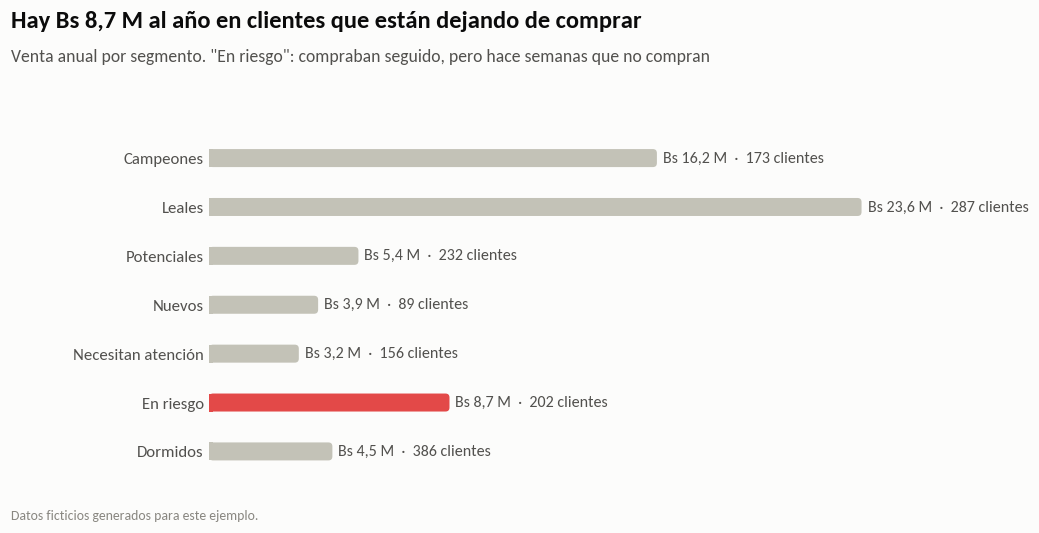

In [7]:
fig, ax = g.figura(alto=5.0, ejes=(0.20, 0.10, 0.70, 0.64))
g.encabezado(fig, f"Hay {g.bs_compacto(en_riesgo['venta_anual_bs'])} al año en clientes que están dejando de comprar",
             "Venta anual por segmento. \"En riesgo\": compraban seguido, pero hace semanas que no compran")
g.barras_horizontales(
    ax, resumen.index, resumen["venta_anual_bs"].values,
    [g.ROJO if s == "En riesgo" else g.GRIS for s in resumen.index],
    textos=[f"{g.bs_compacto(v)}  ·  {int(n)} clientes" for v, n in zip(resumen["venta_anual_bs"], resumen["clientes"])])
g.pie(fig)
g.guardar(fig, IMG / "02_ventas_por_segmento.png")

PosixPath('img/03_peso_de_cada_segmento.png')

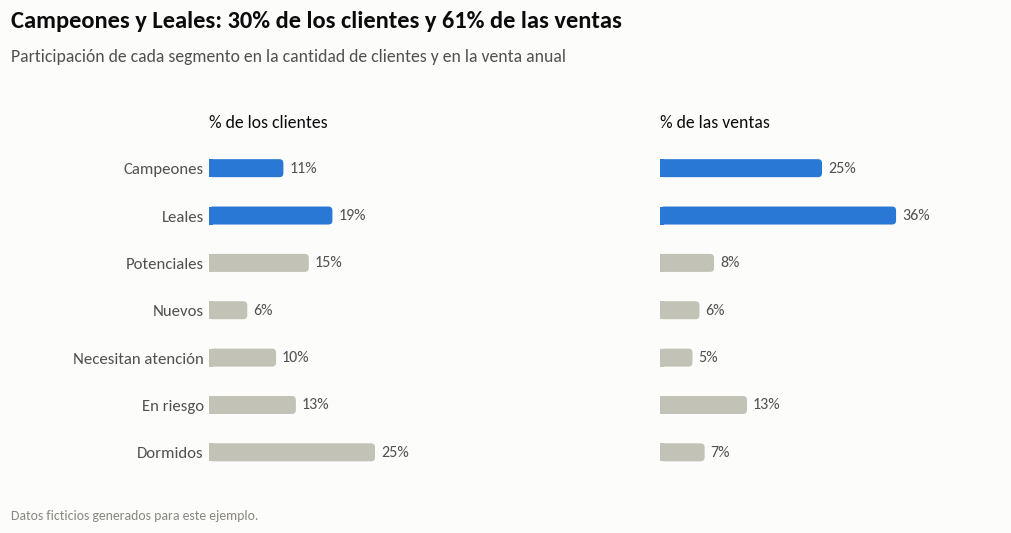

In [8]:
fig = plt.figure(figsize=(10, 5.0))
g.encabezado(fig, f"Campeones y Leales: {g.porcentaje(nucleo['pct_clientes'].sum())} de los clientes y "
                  f"{g.porcentaje(nucleo['pct_ventas'].sum())} de las ventas",
             "Participación de cada segmento en la cantidad de clientes y en la venta anual")
colores = [g.AZUL if s in ("Campeones", "Leales") else g.GRIS for s in resumen.index]
for i, (columna, titulo) in enumerate([("pct_clientes", "% de los clientes"), ("pct_ventas", "% de las ventas")]):
    ax = fig.add_axes((0.20 + i * 0.41, 0.10, 0.31, 0.62))
    g.barras_horizontales(ax, resumen.index, resumen[columna].values, colores,
                          textos=[g.porcentaje(v) for v in resumen[columna]], x_max=0.52)
    ax.set_title(titulo, loc="left", fontsize=11.5, color=g.TINTA, pad=8)
    if i == 1:
        ax.set_yticklabels([])
g.pie(fig)
g.guardar(fig, IMG / "03_peso_de_cada_segmento.png")

## 4. ¿Sirve la segmentación? Prueba con el año anterior

Una segmentación vale si anticipa lo que va a pasar. Para probarlo, se segmenta a los clientes **como estaban el 30/09/2025** y se mira qué hicieron en los 12 meses siguientes:

- **Siguió comprando:** compró algo en el último trimestre (julio a septiembre de 2026).
- **Cambio en ventas:** lo que compró en los 12 meses siguientes frente a su venta anual de antes.

In [9]:
CORTE_ANTERIOR = pd.Timestamp("2025-09-30")
antes = tabla_rfm(ventas, clientes, CORTE_ANTERIOR)

siguiente = ventas[ventas["fecha"].between(CORTE_ANTERIOR + pd.Timedelta(days=1), CORTE)]
antes["venta_siguiente_bs"] = siguiente.groupby("id_cliente")["monto_bs"].sum().reindex(antes.index).fillna(0)
ultimo_trimestre = siguiente[siguiente["fecha"] > CORTE - pd.DateOffset(months=3)]
antes["siguio_comprando"] = antes.index.isin(ultimo_trimestre["id_cliente"])

validacion = antes.groupby("segmento").agg(
    clientes=("R", "size"),
    siguio_comprando=("siguio_comprando", "mean"),
    venta_anual_bs=("venta_anual_bs", "sum"),
    venta_siguiente_bs=("venta_siguiente_bs", "sum"),
).reindex(SEGMENTOS)
validacion["cambio_ventas"] = validacion["venta_siguiente_bs"] / validacion["venta_anual_bs"] - 1

caida_riesgo = -validacion.loc["En riesgo", "cambio_ventas"]
print(f"De los clientes 'En riesgo' de hace un año, {g.porcentaje(validacion.loc['En riesgo', 'siguio_comprando'])} "
      f"siguió comprando y sus ventas cayeron {g.porcentaje(caida_riesgo)}")
print(f"Campeones: {g.porcentaje(validacion.loc['Campeones', 'siguio_comprando'])} siguió comprando")
validacion

De los clientes 'En riesgo' de hace un año, 68% siguió comprando y sus ventas cayeron 35%
Campeones: 92% siguió comprando


,clientes,siguio_comprando,venta_anual_bs,venta_siguiente_bs,cambio_ventas
segmento,,,,,
Campeones,165,0.92,"14,972,024.24","13,539,120.00",-0.10
Leales,288,0.90,"22,661,762.01","21,012,618.00",-0.07
Potenciales,219,0.84,"4,865,134.71","4,669,281.00",-0.04
Nuevos,69,0.74,"2,130,175.78","1,655,661.00",-0.22
Necesitan atención,155,0.79,"2,608,504.32","2,429,263.00",-0.07
En riesgo,192,0.68,"10,082,950.88","6,592,180.00",-0.35
Dormidos,365,0.32,"4,032,375.10","1,943,444.00",-0.52


PosixPath('img/04_validacion.png')

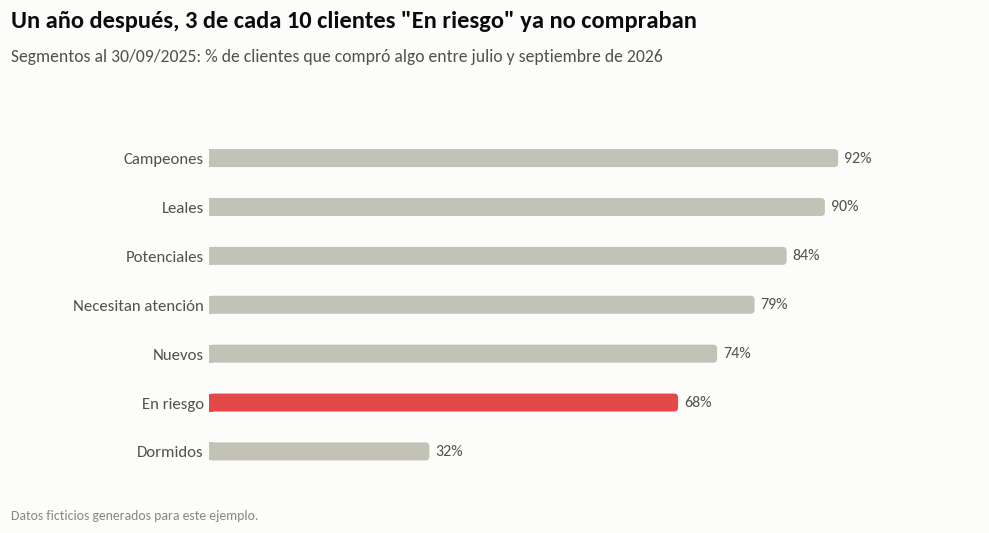

In [10]:
orden = validacion.sort_values("siguio_comprando", ascending=False)
perdidos_riesgo = 1 - validacion.loc["En riesgo", "siguio_comprando"]

fig, ax = g.figura(alto=5.0, ejes=(0.20, 0.10, 0.70, 0.64))
g.encabezado(fig, f"Un año después, {round(perdidos_riesgo * 10)} de cada 10 clientes \"En riesgo\" ya no compraban",
             "Segmentos al 30/09/2025: % de clientes que compró algo entre julio y septiembre de 2026")
g.barras_horizontales(
    ax, orden.index, orden["siguio_comprando"].values,
    [g.ROJO if s == "En riesgo" else g.GRIS for s in orden.index],
    textos=[g.porcentaje(v) for v in orden["siguio_comprando"]], x_max=1.12)
g.pie(fig)
g.guardar(fig, IMG / "04_validacion.png")

## 5. ¿Cuánta plata está en juego?

Si a los clientes que hoy están "En riesgo" les pasa lo mismo que a los del año anterior, sus compras caerían en la misma proporción. Esa caída es la plata que se pierde si no se hace nada. Para priorizar, se ordena a los clientes en riesgo por su venta anual.

In [11]:
riesgo = rfm[rfm["segmento"] == "En riesgo"].sort_values("venta_anual_bs", ascending=False)
venta_en_riesgo = riesgo["venta_anual_bs"].sum()
perdida_esperada = venta_en_riesgo * caida_riesgo
recuperable = perdida_esperada / 2

top = 50
peso_top = riesgo["venta_anual_bs"].head(top).sum() / venta_en_riesgo
print(f"Venta anual de los {len(riesgo)} clientes en riesgo: {g.bs(venta_en_riesgo)}")
print(f"Pérdida esperada si no se hace nada (caída de {g.porcentaje(caida_riesgo)}): {g.bs(perdida_esperada)}")
print(f"Si se recupera la mitad de esa caída: {g.bs(recuperable)} al año")
print(f"Los {top} clientes en riesgo más grandes son el {g.porcentaje(peso_top)} de esa venta")
riesgo.groupby("tipo")["venta_anual_bs"].agg(["size", "sum"]).sort_values("sum", ascending=False)

Venta anual de los 202 clientes en riesgo: Bs 8.688.354
Pérdida esperada si no se hace nada (caída de 35%): Bs 3.007.954
Si se recupera la mitad de esa caída: Bs 1.503.977 al año
Los 50 clientes en riesgo más grandes son el 65% de esa venta


,size,sum
tipo,,
Minimercado,45,"2,803,786.28"
Mayorista,10,"2,607,626.06"
Tienda de barrio,108,"2,295,435.37"
Restaurante o pensión,20,"770,732.78"
Kiosco,19,"210,773.11"


### ¿Dónde se están yendo los clientes?

Por ruta de preventa: qué parte de los clientes de cada ruta está "En riesgo" o "Dormido".

In [12]:
rfm["perdido_o_en_riesgo"] = rfm["segmento"].isin(["En riesgo", "Dormidos"])
por_ruta = rfm.groupby("ruta").agg(
    clientes=("R", "size"), perdido_o_en_riesgo=("perdido_o_en_riesgo", "mean"),
    venta_en_riesgo_bs=("venta_anual_bs", lambda s: s[rfm.loc[s.index, "segmento"] == "En riesgo"].sum()),
).sort_values("perdido_o_en_riesgo", ascending=False)
promedio_rutas = rfm["perdido_o_en_riesgo"].mean()
rutas_criticas = por_ruta[por_ruta["perdido_o_en_riesgo"] >= 0.50].index.tolist()
print(f"Promedio de la empresa: {g.porcentaje(promedio_rutas)} de los clientes perdidos o en riesgo")
print(f"Rutas con la mitad o más: {', '.join(rutas_criticas)}")
por_ruta.head(8)

Promedio de la empresa: 39% de los clientes perdidos o en riesgo
Rutas con la mitad o más: R07, R15, R11


,clientes,perdido_o_en_riesgo,venta_en_riesgo_bs
ruta,,,
R07,53,0.55,"450,147.27"
R15,64,0.52,"102,887.35"
R11,68,0.50,"747,167.06"
R21,56,0.46,"285,278.26"
R03,62,0.45,"285,535.44"
R18,58,0.45,"969,948.90"
R23,68,0.44,"273,742.08"
R08,61,0.43,"218,436.65"


PosixPath('img/05_rutas.png')

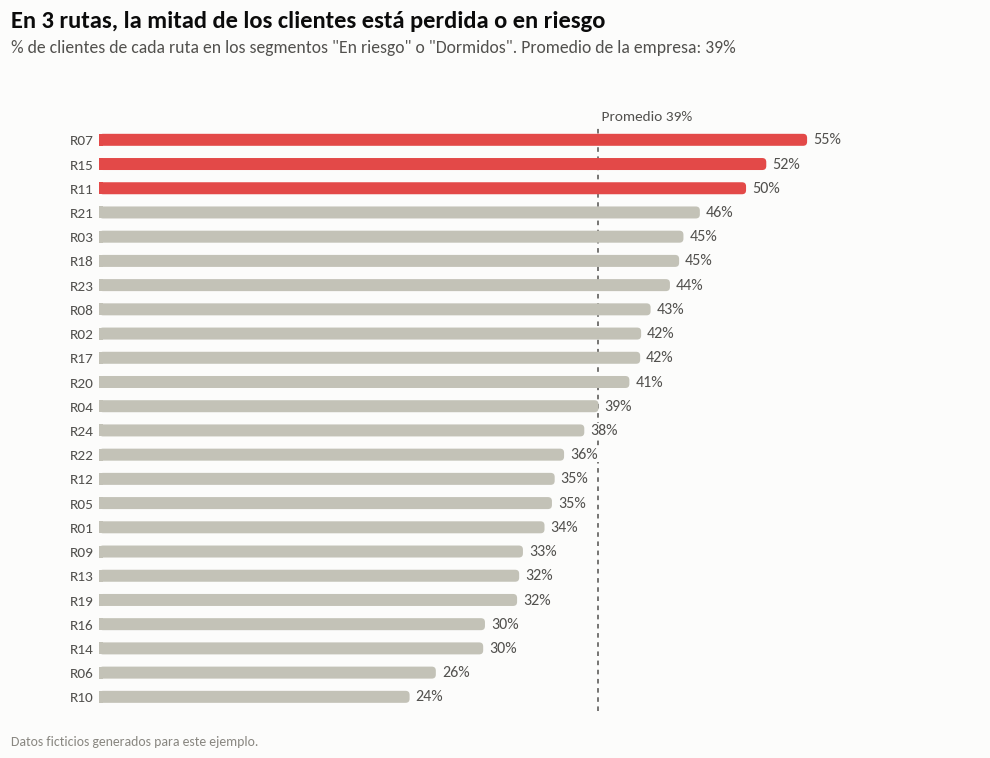

In [13]:
fig, ax = g.figura(alto=7.2, ejes=(0.10, 0.07, 0.80, 0.74))
g.encabezado(fig, f"En {len(rutas_criticas)} rutas, la mitad de los clientes está perdida o en riesgo",
             f"% de clientes de cada ruta en los segmentos \"En riesgo\" o \"Dormidos\". "
             f"Promedio de la empresa: {g.porcentaje(promedio_rutas)}")
g.barras_horizontales(
    ax, por_ruta.index, por_ruta["perdido_o_en_riesgo"].values,
    [g.ROJO if r in rutas_criticas else g.GRIS for r in por_ruta.index],
    textos=[g.porcentaje(v) for v in por_ruta["perdido_o_en_riesgo"]], grosor_px=12, x_max=0.68)
fig.texts[1].set_y(0.918)  # subtítulo más cerca del título en esta figura más alta
for texto in ax.texts:  # la línea del promedio pasa por detrás de las etiquetas
    texto.set_bbox(dict(facecolor=g.SUPERFICIE, edgecolor="none", pad=0.5))
ax.axvline(promedio_rutas, color=g.TINTA_2, linewidth=1, linestyle=(0, (3, 3)), zorder=0)
ax.text(promedio_rutas, len(por_ruta) - 0.3, f" Promedio {g.porcentaje(promedio_rutas)}", fontsize=10,
        color=g.TINTA_2, va="bottom")
ax.tick_params(axis="y", labelsize=10)
g.pie(fig)
g.guardar(fig, IMG / "05_rutas.png")

## 6. Contraste con k-means

Las reglas RFM son fáciles de explicar, pero las definió una persona. Como contraste, se agrupa a los clientes con **k-means**, un algoritmo que no conoce las reglas.

- **Variables:** las mismas tres (recencia, pedidos por mes y compra mensual), en logaritmo y estandarizadas.
- **Cantidad de grupos:** se elige con el coeficiente de silueta.

La pregunta es si un método automático encuentra los mismos grupos y, sobre todo, si aísla a los clientes que se están yendo.

In [14]:
X = StandardScaler().fit_transform(np.log1p(rfm[["recencia_dias", "pedidos_por_mes", "compra_mensual_bs"]]))
siluetas, modelos = {}, {}
for k in range(2, 9):
    modelos[k] = KMeans(n_clusters=k, n_init=10, random_state=2026).fit(X)
    siluetas[k] = silhouette_score(X, modelos[k].labels_)
print("Silueta por cantidad de grupos:")
print(pd.Series(siluetas).round(2).to_string())

# Con k = 2 la separación es solo entre los que compran y los que dejaron de comprar
rfm["grupo_k2"] = modelos[2].labels_
rfm.groupby("grupo_k2").agg(clientes=("R", "size"), recencia_mediana_dias=("recencia_dias", "median"),
                            pedidos_por_mes=("pedidos_por_mes", "median"))

Silueta por cantidad de grupos:
2   0.44
3   0.33
4   0.28
5   0.28
6   0.29
7   0.27
8   0.28


,clientes,recencia_mediana_dias,pedidos_por_mes
grupo_k2,,,
0,1128,5.00,3.50
1,397,98.00,1.33


Con k = 2 la silueta es la más alta, pero solo separa a los que siguen comprando de los que ya no compran: no agrega nada. Entre 3 y 8 grupos, la mejor silueta es la de **k = 3**.

In [15]:
K = 3
rfm["grupo"] = modelos[K].labels_
perfil = rfm.groupby("grupo").agg(
    clientes=("R", "size"), recencia_dias=("recencia_dias", "median"),
    pedidos_por_mes=("pedidos_por_mes", "median"), compra_mensual_bs=("compra_mensual_bs", "median"))
# Nombre de cada grupo según su perfil: el de mayor recencia es el de los inactivos;
# entre los otros, el de mayor compra mensual es el de los grandes
inactivo = perfil["recencia_dias"].idxmax()
activos = perfil.drop(index=inactivo).sort_values("compra_mensual_bs", ascending=False)
nombres = {inactivo: "Inactivos", activos.index[0]: "Grandes y frecuentes", activos.index[1]: "Chicos y medianos"}
rfm["grupo_nombre"] = rfm["grupo"].map(nombres)
perfil.index = perfil.index.map(nombres)
print(f"Silueta con k = {K}: {siluetas[K]:.2f}")
perfil.loc[["Grandes y frecuentes", "Chicos y medianos", "Inactivos"]]

Silueta con k = 3: 0.33


,clientes,recencia_dias,pedidos_por_mes,compra_mensual_bs
grupo,,,,
Grandes y frecuentes,631,4.00,4.50,"3,697.53"
Chicos y medianos,689,12.00,2.50,980.67
Inactivos,205,232.00,0.67,209.68


In [16]:
ORDEN_GRUPOS = ["Grandes y frecuentes", "Chicos y medianos", "Inactivos"]
cruce = pd.crosstab(rfm["segmento"], rfm["grupo_nombre"], normalize="index").reindex(index=SEGMENTOS, columns=ORDEN_GRUPOS)
coincidencia = adjusted_rand_score(rfm["segmento"], rfm["grupo"])
riesgo_por_grupo = cruce.loc["En riesgo"]
print(f"Campeones en 'Grandes y frecuentes': {g.porcentaje(cruce.loc['Campeones', 'Grandes y frecuentes'])}")
print(f"Clientes 'En riesgo' repartidos: {g.porcentaje(riesgo_por_grupo['Grandes y frecuentes'])} en 'Grandes y frecuentes', "
      f"{g.porcentaje(riesgo_por_grupo['Chicos y medianos'])} en 'Chicos y medianos', "
      f"{g.porcentaje(riesgo_por_grupo['Inactivos'])} en 'Inactivos'")
print(f"Índice de Rand ajustado entre segmentos RFM y grupos de k-means: {coincidencia:.2f}")
(cruce * 100).round(0)

Campeones en 'Grandes y frecuentes': 97%
Clientes 'En riesgo' repartidos: 35% en 'Grandes y frecuentes', 65% en 'Chicos y medianos', 0% en 'Inactivos'
Índice de Rand ajustado entre segmentos RFM y grupos de k-means: 0.17


grupo_nombre,Grandes y frecuentes,Chicos y medianos,Inactivos
segmento,,,
Campeones,97.00,3.00,0.00
Leales,86.00,14.00,0.00
Potenciales,34.00,66.00,0.00
Nuevos,54.00,39.00,7.00
Necesitan atención,11.00,88.00,1.00
En riesgo,35.00,65.00,0.00
Dormidos,0.00,48.00,51.00


PosixPath('img/06_kmeans.png')

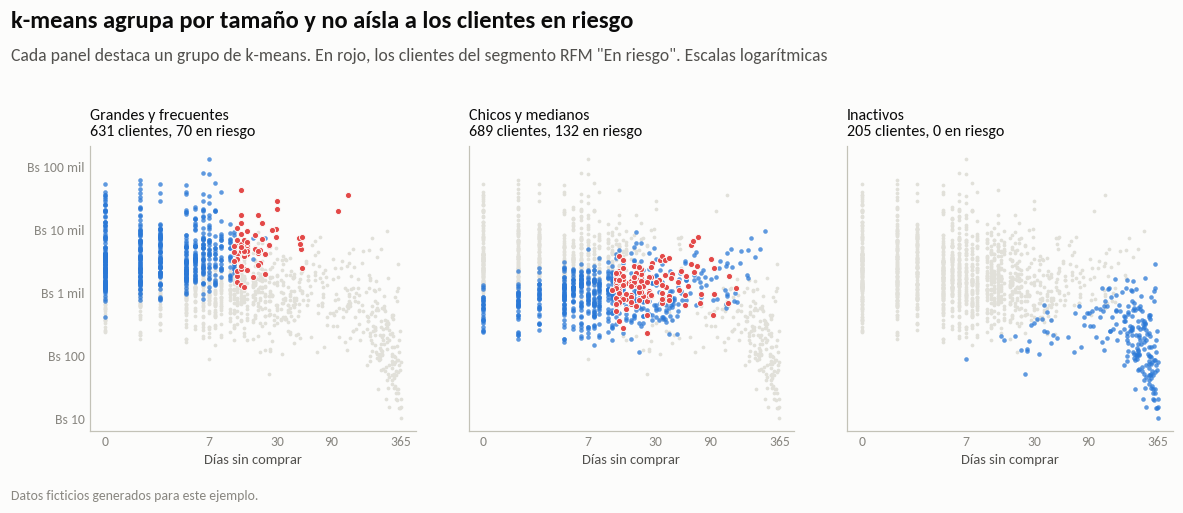

In [17]:
fig = plt.figure(figsize=(12, 4.8))
g.encabezado(fig, "k-means agrupa por tamaño y no aísla a los clientes en riesgo",
             "Cada panel destaca un grupo de k-means. En rojo, los clientes del segmento RFM \"En riesgo\". "
             "Escalas logarítmicas")
dias = [0, 7, 30, 90, 365]
ancho = 0.86 / len(ORDEN_GRUPOS)
for i, nombre in enumerate(ORDEN_GRUPOS):
    ax = fig.add_axes((0.08 + i * ancho, 0.16, ancho - 0.04, 0.54))
    en_grupo = rfm["grupo_nombre"] == nombre
    en_riesgo_grupo = en_grupo & (rfm["segmento"] == "En riesgo")
    ax.scatter(rfm.loc[~en_grupo, "recencia_dias"] + 1, rfm.loc[~en_grupo, "compra_mensual_bs"],
               s=6, color=g.GRILLA, linewidths=0)
    ax.scatter(rfm.loc[en_grupo & ~en_riesgo_grupo, "recencia_dias"] + 1,
               rfm.loc[en_grupo & ~en_riesgo_grupo, "compra_mensual_bs"], s=9, color=g.AZUL, linewidths=0, alpha=0.75)
    ax.scatter(rfm.loc[en_riesgo_grupo, "recencia_dias"] + 1, rfm.loc[en_riesgo_grupo, "compra_mensual_bs"],
               s=16, color=g.ROJO, edgecolors=g.SUPERFICIE, linewidths=0.6)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks([d + 1 for d in dias])
    ax.set_xticklabels([str(d) for d in dias])
    ax.minorticks_off()
    ax.set_title(f"{nombre}\n{int(en_grupo.sum())} clientes, {int(en_riesgo_grupo.sum())} en riesgo",
                 loc="left", fontsize=10.5, color=g.TINTA)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: g.bs_compacto(v)))
    ax.tick_params(axis="both", labelsize=9, colors=g.TENUE)
    ax.spines["left"].set_visible(True)
    if i > 0:
        ax.set_yticklabels([])
    ax.set_xlabel("Días sin comprar", fontsize=9.5, color=g.TINTA_2)
g.pie(fig)
g.guardar(fig, IMG / "06_kmeans.png")

k-means coincide con RFM en los extremos: casi todos los Campeones caen en "Grandes y frecuentes" y la mitad de los Dormidos en "Inactivos". Pero **reparte a los clientes en riesgo entre los dos grupos activos**. Lo que los distingue, haber comprado seguido y dejar de hacerlo hace poco, es una combinación de recencia y frecuencia que el algoritmo no prioriza.

Conclusión: para retener clientes sirven más las reglas RFM. k-means responde otra pregunta, la del tamaño del cliente, que sirve para decidir a quién asignar un ejecutivo de cuentas.

## 7. Qué hacer con cada segmento

| Segmento | Objetivo | Acción sugerida |
|---|---|---|
| Campeones | Cuidarlos | Abastecimiento prioritario, sin quiebres de stock; visita del supervisor; acuerdos de exhibición. |
| Leales | Subir el ticket | Combos y lanzamientos; ofrecer las familias que todavía no compran. |
| Potenciales | Subir la frecuencia | Día fijo de visita; promociones por volumen. |
| Nuevos | Lograr la segunda y tercera compra | Seguimiento en las primeras semanas; condiciones de entrada. |
| Necesitan atención | Entender qué cambió | Preguntar en la próxima visita; revisar precios y surtido frente a la competencia. |
| En riesgo | Recuperarlos ya | Visita del supervisor a los más grandes primero; oferta de reactivación. |
| Dormidos | Recuperar barato | Llamada o mensaje; no gastar visitas presenciales. |

La lista completa con el segmento, la acción y la prioridad de cada cliente queda en `resultados/clientes_segmentados.csv`.

In [18]:
ACCIONES = {
    "Campeones": "Cuidar: abastecimiento prioritario y visita del supervisor",
    "Leales": "Subir el ticket: combos y familias que no compra",
    "Potenciales": "Subir la frecuencia: día fijo de visita",
    "Nuevos": "Asegurar la segunda y tercera compra",
    "Necesitan atención": "Preguntar qué cambió en la próxima visita",
    "En riesgo": "Recuperar: visita del supervisor y oferta de reactivación",
    "Dormidos": "Recuperar barato: llamada o mensaje",
}
salida = rfm.reset_index()[["id_cliente", "tipo", "zona", "ruta", "segmento", "recencia_dias", "pedidos_por_mes",
                            "compra_mensual_bs", "venta_anual_bs", "R", "F", "M"]].copy()
salida["accion_sugerida"] = salida["segmento"].map(ACCIONES)
salida["orden_segmento"] = salida["segmento"].map({s: i for i, s in enumerate(SEGMENTOS)})
salida = salida.sort_values(["orden_segmento", "venta_anual_bs"], ascending=[True, False]).drop(columns="orden_segmento")
salida["prioridad_en_segmento"] = salida.groupby("segmento").cumcount() + 1
salida = salida.round({"pedidos_por_mes": 1, "compra_mensual_bs": 0, "venta_anual_bs": 0})
salida.to_csv(RESULTADOS / "clientes_segmentados.csv", index=False, encoding="utf-8")
print(f"Guardado: resultados/clientes_segmentados.csv ({len(salida):,} clientes)")
salida[salida["segmento"] == "En riesgo"].head(10)

Guardado: resultados/clientes_segmentados.csv (1,525 clientes)


,id_cliente,tipo,zona,ruta,segmento,recencia_dias,pedidos_por_mes,compra_mensual_bs,venta_anual_bs,R,F,M,accion_sugerida,prioridad_en_segmento
781,C0963,Mayorista,Oeste,R18,En riesgo,14,5.80,"42,730.00","512,759.00",2,5,5,Recuperar: visita del supervisor y oferta de r...,1
709,C0872,Mayorista,Norte,R05,En riesgo,126,6.00,"36,260.00","435,122.00",1,5,5,Recuperar: visita del supervisor y oferta de r...,2
149,C0180,Mayorista,Este,R14,En riesgo,30,5.70,"28,685.00","344,216.00",2,5,5,Recuperar: visita del supervisor y oferta de r...,3
472,C0585,Mayorista,Este,R12,En riesgo,30,6.80,"21,781.00","261,375.00",2,5,5,Recuperar: visita del supervisor y oferta de r...,4
102,C0128,Mayorista,Norte,R01,En riesgo,102,3.30,"20,042.00","240,509.00",1,3,5,Recuperar: visita del supervisor y oferta de r...,5
1203,C1458,Mayorista,Norte,R02,En riesgo,20,6.00,"17,117.00","205,402.00",2,5,5,Recuperar: visita del supervisor y oferta de r...,6
61,C0079,Mayorista,Sur,R07,En riesgo,14,3.30,"17,037.00","204,448.00",2,3,5,Recuperar: visita del supervisor y oferta de r...,7
33,C0045,Mayorista,Centro,R21,En riesgo,22,3.30,"12,887.00","154,650.00",2,3,5,Recuperar: visita del supervisor y oferta de r...,8
108,C0135,Minimercado,Centro,R24,En riesgo,14,3.70,"12,701.00","152,408.00",2,4,5,Recuperar: visita del supervisor y oferta de r...,9
368,C0459,Mayorista,Norte,R03,En riesgo,13,4.60,"10,711.00","128,528.00",2,4,5,Recuperar: visita del supervisor y oferta de r...,10


## 8. Límites

- Los datos son ficticios. Con datos reales conviene recalcular los cortes de cada nota y repetir la prueba con el año anterior.
- La caída esperada supone que este año se repite lo que pasó el anterior. Es una referencia para dimensionar, no un pronóstico.
- RFM mira solo el comportamiento de compra. No sabe por qué un cliente compra menos: puede ser la competencia, un cambio de dueño o un problema de servicio. La visita sirve para averiguarlo.
- Las rutas con más clientes perdidos son una pista, no un diagnóstico: hay que revisar en terreno la frecuencia de visita, los quiebres de stock y la atención.